In [3]:
!pip install -q pyspark

In [2]:
import random, csv, os
from datetime import datetime, timedelta

random.seed(42)
os.makedirs("data/raw", exist_ok=True)

categories = {"Electronics":(2000,40000),"Clothing":(300,5000),"Books":(100,1500),"Home":(500,15000),"Beauty":(150,3000)}
cities = ["Delhi","Mumbai","Bengaluru","Hyderabad","Chennai","Kolkata","Pune","delhi "," MUMBAI"]
payments = ["UPI","Card","COD","NetBanking"]
start = datetime(2025,1,1)

rows = []
for i in range(1, 50001):
    cat = random.choice(list(categories))
    lo, hi = categories[cat]
    price = round(random.uniform(lo, hi), 2)
    rows.append([
        i, f"C{random.randint(1,3000):04d}", cat,
        price if random.random() > 0.02 else "",
        random.randint(1,5), random.choice(cities), random.choice(payments),
        (start + timedelta(days=random.randint(0,364))).strftime("%Y-%m-%d")
    ])
rows += random.sample(rows, 500)   # duplicate orders

with open("data/raw/orders.csv","w",newline="") as f:
    w = csv.writer(f)
    w.writerow(["order_id","customer_id","category","price","quantity","city","payment_method","order_date"])
    w.writerows(rows)

print(len(rows), "rows written")

50500 rows written


In [4]:
from pyspark.sql import SparkSession, functions as F, Window

spark = SparkSession.builder.appName("EcomETL").master("local[*]").getOrCreate()

raw = spark.read.csv("data/raw/orders.csv", header=True, inferSchema=True)
raw.printSchema()
print("raw rows:", raw.count())
raw.show(5)

root
 |-- order_id: integer (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- category: string (nullable = true)
 |-- price: double (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- city: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- order_date: date (nullable = true)

raw rows: 50500
+--------+-----------+-----------+-------+--------+---------+--------------+----------+
|order_id|customer_id|   category|  price|quantity|     city|payment_method|order_date|
+--------+-----------+-----------+-------+--------+---------+--------------+----------+
|       1|      C1127|Electronics|2950.41|       2|   Mumbai|           UPI|2025-10-30|
|       2|      C0384|       Home| 960.85|       5|    Delhi|          Card|2025-11-29|
|       3|      C1840|     Beauty|1345.63|       1|Bengaluru|    NetBanking|2025-06-24|
|       4|      C1379|      Books| 317.67|       4|   Mumbai|           COD|2025-06-26|
|       5|      C0178|     Beauty| 903

In [5]:
silver = (raw
    .dropDuplicates(["order_id"])
    .dropna(subset=["price"])
    .withColumn("city", F.initcap(F.trim("city")))
    .withColumn("order_date", F.to_date("order_date"))
    .withColumn("revenue", F.round(F.col("price") * F.col("quantity"), 2))
    .withColumn("month", F.date_format("order_date", "yyyy-MM"))
)

print("raw:", raw.count(), "| clean:", silver.count(), "| removed:", raw.count() - silver.count())

silver.write.mode("overwrite").partitionBy("month").parquet("data/silver/orders")

raw: 50500 | clean: 48948 | removed: 1552


In [6]:
silver = spark.read.parquet("data/silver/orders")
silver.createOrReplaceTempView("orders")

monthly = spark.sql("""
    SELECT month, ROUND(SUM(revenue),2) AS revenue, COUNT(*) AS orders
    FROM orders GROUP BY month ORDER BY month
""")
monthly.show(12)

category_rev = spark.sql("""
    SELECT category, ROUND(SUM(revenue),2) AS revenue, ROUND(AVG(revenue),2) AS avg_order_value
    FROM orders GROUP BY category ORDER BY revenue DESC
""")
category_rev.show()

top_customers = spark.sql("""
    SELECT customer_id, ROUND(SUM(revenue),2) AS total_spent,
           RANK() OVER (ORDER BY SUM(revenue) DESC) AS rnk
    FROM orders GROUP BY customer_id ORDER BY rnk LIMIT 10
""")
top_customers.show()

# Window function in PySpark: best category in each city
w = Window.partitionBy("city").orderBy(F.desc("revenue"))
best_per_city = (silver.groupBy("city","category")
    .agg(F.sum("revenue").alias("revenue"))
    .withColumn("rank", F.row_number().over(w))
    .filter("rank = 1"))
best_per_city.show()

+-------+-------------+------+
|  month|      revenue|orders|
+-------+-------------+------+
|2025-01|8.439030693E7|  4192|
|2025-02|7.555105328E7|  3778|
|2025-03|8.321966327E7|  4165|
|2025-04|7.835070088E7|  4102|
|2025-05|8.524216258E7|  4112|
|2025-06|8.074639808E7|  3968|
|2025-07|8.475552034E7|  4162|
|2025-08|8.361770708E7|  4176|
|2025-09|7.821787571E7|  4009|
|2025-10|8.129242101E7|  4066|
|2025-11|7.968834474E7|  4027|
|2025-12|8.349801154E7|  4191|
+-------+-------------+------+

+-----------+--------------+---------------+
|   category|       revenue|avg_order_value|
+-----------+--------------+---------------+
|Electronics|6.0842180271E8|       62840.51|
|       Home|2.2207759511E8|       22875.73|
|   Clothing| 7.771748524E7|        7907.76|
|     Beauty| 4.690125805E7|        4756.24|
|      Books| 2.345202433E7|        2376.33|
+-----------+--------------+---------------+

+-----------+-----------+---+
|customer_id|total_spent|rnk|
+-----------+-----------+---+
|      

<Axes: title={'center': 'Monthly Revenue'}, xlabel='month'>

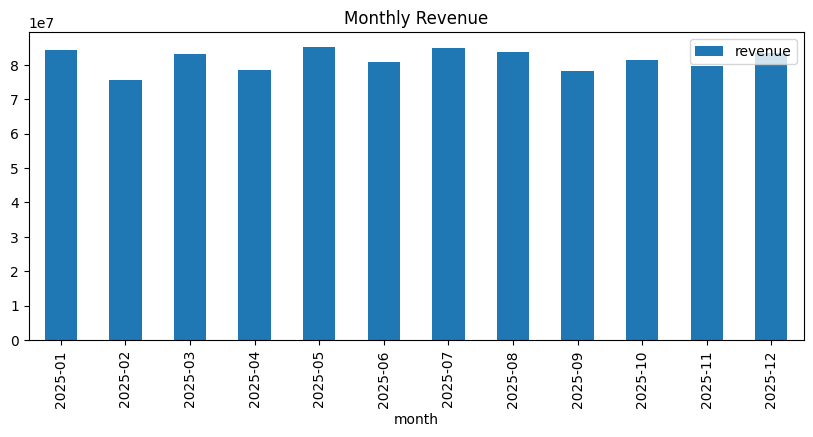

In [7]:
monthly.write.mode("overwrite").parquet("data/gold/monthly_revenue")
category_rev.write.mode("overwrite").parquet("data/gold/category_revenue")
top_customers.write.mode("overwrite").parquet("data/gold/top_customers")

monthly.toPandas().plot(x="month", y="revenue", kind="bar", figsize=(10,4), title="Monthly Revenue")